### PCAの簡単な例

**データ作成からデータ解析**

簡単なPCAの例を以下に書きます。この例は
https://scikit-learn.org/stable/auto_examples/cross_decomposition/plot_pcr_vs_pls.html#sphx-glr-auto-examples-cross-decomposition-plot-pcr-vs-pls-py
からとっています。

In [1]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline


In [2]:
# データ作成
g_dfraw = pd.read_csv("../data/anisotropicdata1.csv")
g_desriptor_labels = ["x1", "x2"]
g_target_name = "y"
g_dfraw

,x1,x2,y
0,-2.899973,-0.488814,1.0
1,-3.687915,-0.820873,1.0
2,0.861180,-3.790616,1.0
3,-2.755710,0.097817,0.0
4,-2.778721,-0.465727,1.0
...,...,...,...
295,-2.129876,-0.039154,0.0
296,-2.811709,1.002719,0.0
297,-1.862399,-0.962688,0.0
298,-3.556608,0.641604,0.0


もともと二次元のデータですが、
PCAを用いて同じく二次元の長軸、短軸に変換します。

In [3]:

g_Xraw = g_dfraw.loc[:, g_desriptor_labels].values
g_label = g_dfraw.loc[:, g_target_name].values
# データプリプロセス
g_scaler = StandardScaler()
g_scaler.fit(g_Xraw)
g_X = g_scaler.transform(g_Xraw)
# データ解析
g_pca = PCA(2)
g_pca.fit(g_X)
g_X_pca = g_pca.transform(g_X)


**可視化**

変換前と変換後の変化を図示します。

/tmp/mi-in-place.WyFyuX/ipykernel_10653/3624115936.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


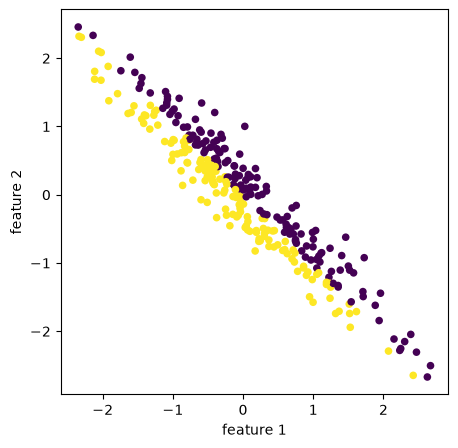

In [4]:
def plot_data2d(X, y0=None):
    """plot explanatory variables and optionally target variable.

    Args:
        X (np.array): descriptors
        y0 (np.array, optional): target variable. Defaults to None.
    """
    fig, ax = plt.subplots(figsize=(5, 5))
    if y0 is not None:
        y = y0.ravel()
        ax.scatter(X[:, 0], X[:, 1], c=y, linewidths=0, s=30)
    else:
        ax.scatter(X[:, 0], X[:, 1], linewidths=0, s=30)
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
    fig.show()
    
plot_data2d(g_X, g_label)


Scaled original data
PCA transformed data


/tmp/mi-in-place.WyFyuX/ipykernel_10653/3624115936.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


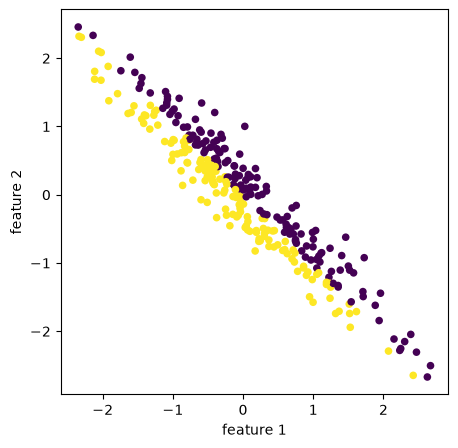

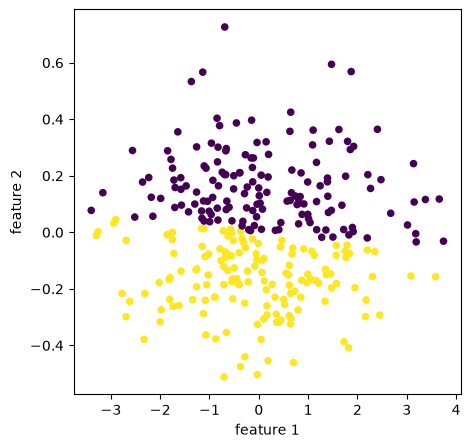

In [5]:
print("Scaled original data")
plot_data2d(g_X, g_label)
print ("PCA transformed data")
plot_data2d(g_X_pca, g_label)

上の例のように分布の短軸側の変数に目的変数が依存している場合もあります。
その場合にPCAの長軸側から変数選択を行うと目的変数が全く説明できません。



**コメント**

yの分散も用いて説明変数の次元圧縮を行うPLSという線形回帰手法があります。

ref. 
https://scikit-learn.org/stable/modules/generated/sklearn.cross_decomposition.PLSRegression.html
